In [19]:
import yfinance as yf
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt


In [20]:
start = '2022-01-01'
end = '2025-01-01'
stocks = ['SONY', 'TM', 'HMC','MUFG', 'MFG','NMR','TAK']  # Basket of Japanese stocks
fx_pair = 'USDJPY=X'
z_entry = 2.0  # Z-score threshold for entry
z_exit = 0.5   # Z-score threshold for exit
lookback = 20  # Lookback period for z-score calculation



In [21]:
# Download data
assets = stocks + [fx_pair]
df = yf.download(assets, start=start, end=end)['Close'].dropna()

# Rename columns
df.columns = stocks + ['USDJPY']
df['Basket'] = df[stocks].mean(axis=1)  # Equal-weighted basket

# Step 1: Check for cointegration between basket and USDJPY
X = df['Basket'].values.reshape(-1, 1)
y = df['USDJPY'].values
model = sm.OLS(y, sm.add_constant(X)).fit()
df['Spread'] = model.resid

# Test stationarity (ADF test)
adf_result = adfuller(df['Spread'])
print(f"ADF Statistic: {adf_result[0]}")
print(f"P-Value: {adf_result[1]}")
if adf_result[1] < 0.05:
    print("Spread is stationary (cointegrated)")
else:
    print("Spread is not stationary (not cointegrated)")


/tmp/ipython-input-21-3057336089.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(assets, start=start, end=end)['Close'].dropna()
[*********************100%***********************]  8 of 8 completed

ADF Statistic: -2.5483024906121483
P-Value: 0.10415961393535228
Spread is not stationary (not cointegrated)


/tmp/ipython-input-22-3090302713.py:29: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"Cumulative Return: {cumulative_returns[-1]:.2%}")



Strategy Performance:
Cumulative Return: 10.32%
Sharpe Ratio: 0.43
Win Ratio: 53.33%
Max Drawdown: 10.91%


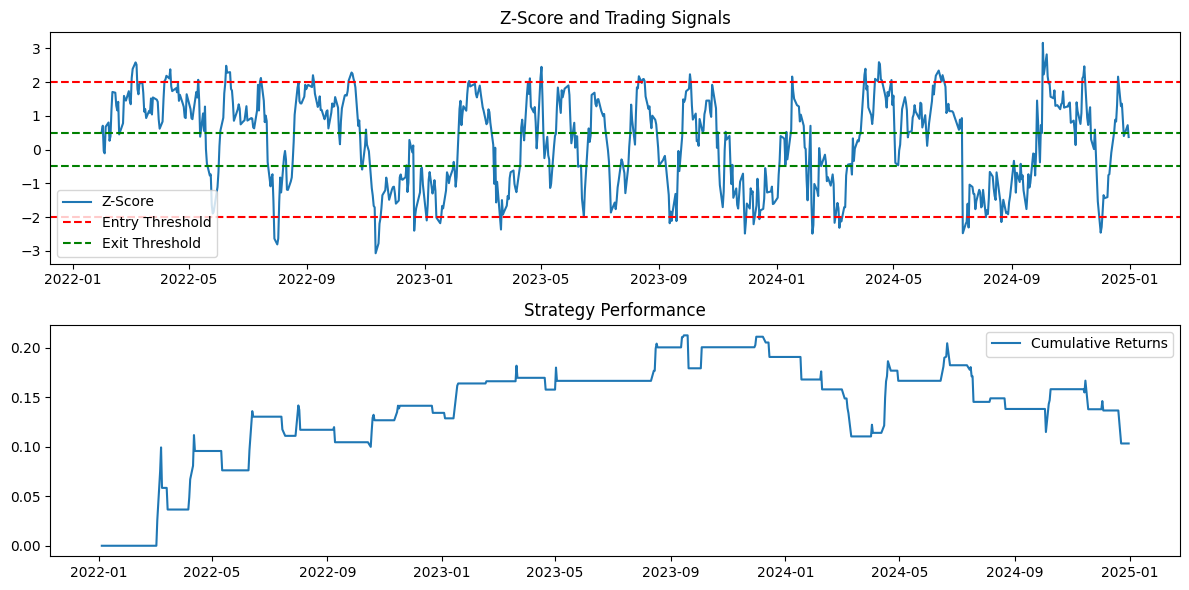

In [22]:
# Step 2: Calculate z-scores
df['Spread_Mean'] = df['Spread'].rolling(window=lookback).mean()
df['Spread_Std'] = df['Spread'].rolling(window=lookback).std()
df['Z_Score'] = (df['Spread'] - df['Spread_Mean']) / df['Spread_Std']

# Step 3: Generate trading signals
df['Position'] = 0
df['Position'] = np.where(df['Z_Score'] > z_entry, -1, df['Position'])  # Short spread
df['Position'] = np.where(df['Z_Score'] < -z_entry, 1, df['Position'])  # Long spread
df['Position'] = np.where(abs(df['Z_Score']) < z_exit, 0, df['Position'])  # Exit
df['Position'] = df['Position'].shift(1).ffill().fillna(0)

# Step 4: Calculate returns
# Spread returns = Basket returns - beta * USDJPY returns
df['Basket_Returns'] = df['Basket'].pct_change()
df['USDJPY_Returns'] = df['USDJPY'].pct_change()
beta = model.params[1]  # Slope from OLS
df['Spread_Returns'] = df['Basket_Returns'] - beta * df['USDJPY_Returns']
df['Strategy_Returns'] = df['Position'] * df['Spread_Returns']

# Step 5: Calculate performance metrics
cumulative_returns = (1 + df['Strategy_Returns']).cumprod() - 1
sharpe_ratio = np.sqrt(252) * df['Strategy_Returns'].mean() / df['Strategy_Returns'].std()
win_ratio = len(df[df['Strategy_Returns'] > 0]) / len(df[df['Strategy_Returns'] != 0])
max_drawdown = (cumulative_returns.cummax() - cumulative_returns).max()

# Print performance metrics
print("\nStrategy Performance:")
print(f"Cumulative Return: {cumulative_returns[-1]:.2%}")
print(f"Sharpe Ratio: {sharpe_ratio:.2f}")
print(f"Win Ratio: {win_ratio:.2%}")
print(f"Max Drawdown: {max_drawdown:.2%}")

# Plot results
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(df.index, df['Z_Score'], label='Z-Score')
plt.axhline(z_entry, color='r', linestyle='--', label='Entry Threshold')
plt.axhline(-z_entry, color='r', linestyle='--')
plt.axhline(z_exit, color='g', linestyle='--', label='Exit Threshold')
plt.axhline(-z_exit, color='g', linestyle='--')
plt.legend()
plt.title('Z-Score and Trading Signals')

plt.subplot(2, 1, 2)
plt.plot(df.index, cumulative_returns, label='Cumulative Returns')
plt.legend()
plt.title('Strategy Performance')
plt.tight_layout()
plt.show()